# Telco customer churn: exploratory analysis

Goal: compare churn rates by contract type, tenure, internet service and payment method. One row is one customer; `Churn = Yes` means the customer left. This is descriptive analysis only: no causal inference and no model.

## 1. Loading the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
display(df[["customerID", "Contract", "tenure", "InternetService", "Churn"]].head())

Shape: (7043, 21)


,customerID,Contract,tenure,InternetService,Churn
0,7590-VHVEG,Month-to-month,1,DSL,No
1,5575-GNVDE,One year,34,DSL,No
2,3668-QPYBK,Month-to-month,2,DSL,Yes
3,7795-CFOCW,One year,45,DSL,No
4,9237-HQITU,Month-to-month,2,Fiber optic,Yes


## 2. Churn flag

`Yes` becomes 1 and `No` becomes 0, so that `sum()` is the number of churners and `mean()` is the churn rate.

In [2]:
df["churn_flag"] = (df["Churn"] == "Yes").astype(int)
display(df[["Churn", "churn_flag"]].head())

customer_count = len(df)
churn_count = df["churn_flag"].sum()
churn_rate_pct = df["churn_flag"].mean() * 100
print(f"Overall: {customer_count} customers, {churn_count} churned, churn rate {churn_rate_pct:.2f}%")

,Churn,churn_flag
0,No,0
1,No,0
2,Yes,1
3,No,0
4,Yes,1


Overall: 7043 customers, 1869 churned, churn rate 26.54%


## 3. By contract type

Group size, churners and churn rate side by side. The percentage column is for reading; the raw rate is kept for later calculations.

In [3]:
display(df["Contract"].value_counts().rename("customer_count").to_frame())

contract_summary = (
    df.groupby("Contract")["churn_flag"]
      .agg(
          customer_count="count",
          churn_count="sum",
          churn_rate="mean",
      )
)
contract_summary["churn_rate_pct"] = (contract_summary["churn_rate"] * 100).round(2)
display(contract_summary)

,customer_count
Contract,
Month-to-month,3875
Two year,1695
One year,1473


,customer_count,churn_count,churn_rate,churn_rate_pct
Contract,,,,
Month-to-month,3875,1655,0.427097,42.71
One year,1473,166,0.112695,11.27
Two year,1695,48,0.028319,2.83


## 4. By tenure

`tenure` is in months. `pd.cut()` places the whole months into four non-overlapping bands: 0–12, 13–24, 25–48, 49–72. The `-1` is only the left edge of the first band, not a real tenure.

In [4]:
display(df["tenure"].describe().to_frame("tenure_months"))

# pd.cut() is left-open, right-closed by default, so (-1, 12] holds the integers 0 to 12
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
)
display(df[["tenure", "tenure_group"]].head())
print("Customers not assigned to a band:", df["tenure_group"].isna().sum())

,tenure_months
count,7043.000000
mean,32.371149
std,24.559481
min,0.000000
25%,9.000000
50%,29.000000
75%,55.000000
max,72.000000


,tenure,tenure_group
0,1,0-12
1,34,25-48
2,2,0-12
3,45,25-48
4,2,0-12


Customers not assigned to a band: 0


In [5]:
tenure_summary = (
    df.groupby("tenure_group", observed=True)["churn_flag"]
      .agg(
          customer_count="count",
          churn_count="sum",
          churn_rate="mean",
      )
)
tenure_summary["churn_rate_pct"] = (tenure_summary["churn_rate"] * 100).round(2)
display(tenure_summary)

,customer_count,churn_count,churn_rate,churn_rate_pct
tenure_group,,,,
0-12,2186,1037,0.474382,47.44
13-24,1024,294,0.287109,28.71
25-48,1594,325,0.203890,20.39
49-72,2239,213,0.095132,9.51


## 5. By internet service

`No` is one of the service categories in the dataset.

In [6]:
internet_service = (
    df.groupby("InternetService")["churn_flag"]
      .agg(
          customer_count="count",
          churn_count="sum",
          churn_rate="mean",
      )
)
internet_service["churn_rate_pct"] = (internet_service["churn_rate"] * 100).round(2)
display(internet_service)

,customer_count,churn_count,churn_rate,churn_rate_pct
InternetService,,,,
DSL,2421,459,0.189591,18.96
Fiber optic,3096,1297,0.418928,41.89
No,1526,113,0.074050,7.40


## 6. Checking group sizes

Each grouping must cover all 7,043 customers.

In [7]:
print("All customers:", len(df))
print("Contract groups:", contract_summary["customer_count"].sum())
print("Tenure groups:", tenure_summary["customer_count"].sum())
print("Internet service groups:", internet_service["customer_count"].sum())

All customers: 7043
Contract groups: 7043
Tenure groups: 7043
Internet service groups: 7043


## 7. Charts

The values were checked in the tables above; the charts use the percentage column, so the y-axis is in %.

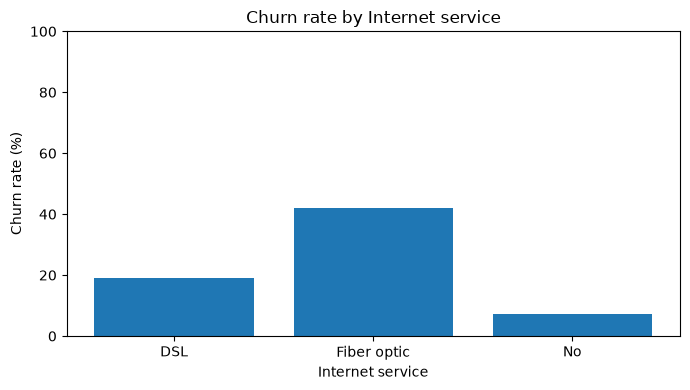

In [8]:
plt.figure(figsize=(7, 4))
plt.bar(internet_service.index, internet_service["churn_rate_pct"])
plt.title("Churn rate by Internet service")
plt.xlabel("Internet service")
plt.ylabel("Churn rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

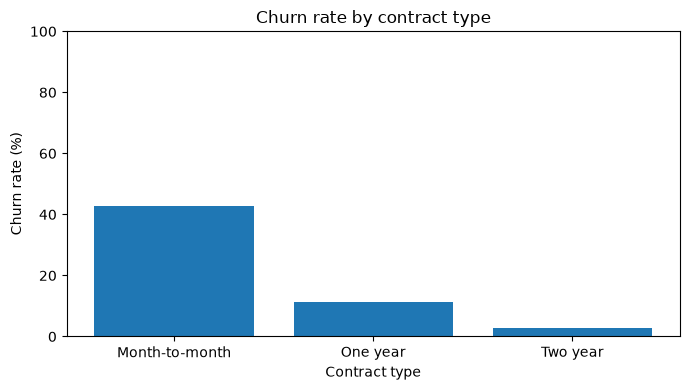

In [9]:
plt.figure(figsize=(7, 4))
plt.bar(contract_summary.index, contract_summary["churn_rate_pct"])
plt.title("Churn rate by contract type")
plt.xlabel("Contract type")
plt.ylabel("Churn rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 8. Observations and limits

1. **Contract type:** 3,875 month-to-month customers, of whom 1,655 churned (42.71%); 1,695 two-year customers, of whom 48 churned (2.83%). A gap of **39.88 percentage points**.
2. **Tenure:** 2,186 customers in the 0–12 month band, of whom 1,037 churned (47.44%); 2,239 in the 49–72 month band, of whom 213 churned (9.51%). A gap of **37.93 percentage points**.
3. **Internet service:** fiber optic 3,096 customers, 1,297 churned (41.89%); DSL 2,421 customers, 459 churned (18.96%); no internet service 1,526 customers, 113 churned (7.40%).

Limits:
1. This is a public sample dataset and does not represent a specific operator or its current customers.
2. These are descriptive differences between groups. The groups may differ in other respects, so nothing here shows that contract type, tenure or service type causes churn.

## 9. Checking against the raw `Churn` column

Counting `Yes`, `No` and missing values directly in the raw column, to confirm it agrees with the `churn_flag` totals.

In [10]:
raw_churn_counts = df["Churn"].value_counts(dropna=False)
display(raw_churn_counts.rename("customer_count").to_frame())

assert set(raw_churn_counts.index) == {"Yes", "No"}
assert raw_churn_counts.sum() == customer_count
assert raw_churn_counts["Yes"] == churn_count

,customer_count
Churn,
No,5174
Yes,1869


## 10. By payment method

The denominator of each churn rate is the size of that group.

In [11]:
payment_method_summary = (
    df.groupby("PaymentMethod")["churn_flag"]
      .agg(
          customer_count="count",
          churn_count="sum",
          churn_rate="mean",
      )
)
payment_method_summary["churn_rate_pct"] = (
    payment_method_summary["churn_rate"] * 100
).round(2)
display(payment_method_summary)

print("Customers across payment methods:", payment_method_summary["customer_count"].sum())
print("Churners across payment methods:", payment_method_summary["churn_count"].sum())
assert payment_method_summary["customer_count"].sum() == customer_count
assert payment_method_summary["churn_count"].sum() == churn_count

,customer_count,churn_count,churn_rate,churn_rate_pct
PaymentMethod,,,,
Bank transfer (automatic),1544,258,0.167098,16.71
Credit card (automatic),1522,232,0.152431,15.24
Electronic check,2365,1071,0.452854,45.29
Mailed check,1612,308,0.191067,19.11


Customers across payment methods: 7043
Churners across payment methods: 1869


The electronic-check group has 2,365 customers and 1,071 churners, a rate of 45.29%. For comparison on another dimension, the month-to-month group has 3,875 customers and a rate of 42.71%. These two groups overlap and belong to different dimensions: the percentages cannot be added, and neither shows that the payment method or the contract type causes churn.

## 11. Chi-square test: contract type and churn

The test asks whether the differences between contract types could plausibly be chance. It says whether an association exists, not how strong it is; effect size is covered in [08-effect-size-risk-profile](08-effect-size-risk-profile.ipynb).

In [12]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["Contract"], df["Churn"])
result = chi2_contingency(table)

print("Observed counts:")
display(table)

print(f"Chi-square statistic: {result.statistic:.2f}")
print(f"p-value: {result.pvalue:.2e}")
print(f"Degrees of freedom: {result.dof}")

expected = pd.DataFrame(
    result.expected_freq,
    index=table.index,
    columns=table.columns,
)
print("Expected counts if contract and churn were unrelated:")
display(expected.round(1))

Observed counts:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square statistic: 1184.60
p-value: 5.86e-258
Degrees of freedom: 2
Expected counts if contract and churn were unrelated:


Churn,No,Yes
Contract,,
Month-to-month,2846.7,1028.3
One year,1082.1,390.9
Two year,1245.2,449.8
